# Plot the period distribution for different metallicities


## imports

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cmap import Colormap
from scipy.stats import gaussian_kde
from posydon.utils.common_functions import convert_metallicity_to_string
from posydon.popsyn.distributions import PowerLawPeriod

from wr_population.paths import FIGURE_DIR, EXTRA_FIGURE_DIR
from wr_population.io import load_metallicity
from wr_population.classification import (classify_WR, make_binary_mask,
                                          formation_channel_masks, CHANNEL_COLOURS)
from wr_population.plotting import METALLICITY_COLOURS, plot_period_histogram

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))
COLORS = METALLICITY_COLOURS
from functools import partial

from wr_population.plotting import use_posydon_style
use_posydon_style()


## Load POSYDON data

In [2]:
metallicities = [0.01, 0.1, 0.2, 0.45, 1.0]  # in units of Zsun

WR_data = {Z: load_metallicity(Z) for Z in metallicities}

In [3]:
# WR selection with a lower optical depth boundary (tau > 0.5)
classify_WR_optical_depth = partial(classify_WR, tau_min=0.5)

In [4]:
# Example: compute WR type fractions for each metallicity
for Z, d in WR_data.items():
    WNL, WNE, WC = classify_WR(d)
    bm = make_binary_mask(d)
    w = d['weight'] * d['model_weight']
    total = np.sum(w[bm & (WNL | WNE | WC)])
    WNL_fraction = np.sum(w[bm & WNL]) / total
    WNE_fraction = np.sum(w[bm & WNE]) / total
    WC_fraction  = np.sum(w[bm & WC])  / total
    print(f"Z = {Z} Zsun  ->  WNL: {WNL_fraction*100:.0f}%  WNE: {WNE_fraction*100:.0f}%  WC: {WC_fraction*100:.0f}%")


Z = 0.01 Zsun  ->  WNL: 72%  WNE: 22%  WC: 6%


Z = 0.1 Zsun  ->  WNL: 61%  WNE: 33%  WC: 6%


Z = 0.2 Zsun  ->  WNL: 52%  WNE: 41%  WC: 7%


Z = 0.45 Zsun  ->  WNL: 29%  WNE: 56%  WC: 15%


Z = 1.0 Zsun  ->  WNL: 14%  WNE: 58%  WC: 28%


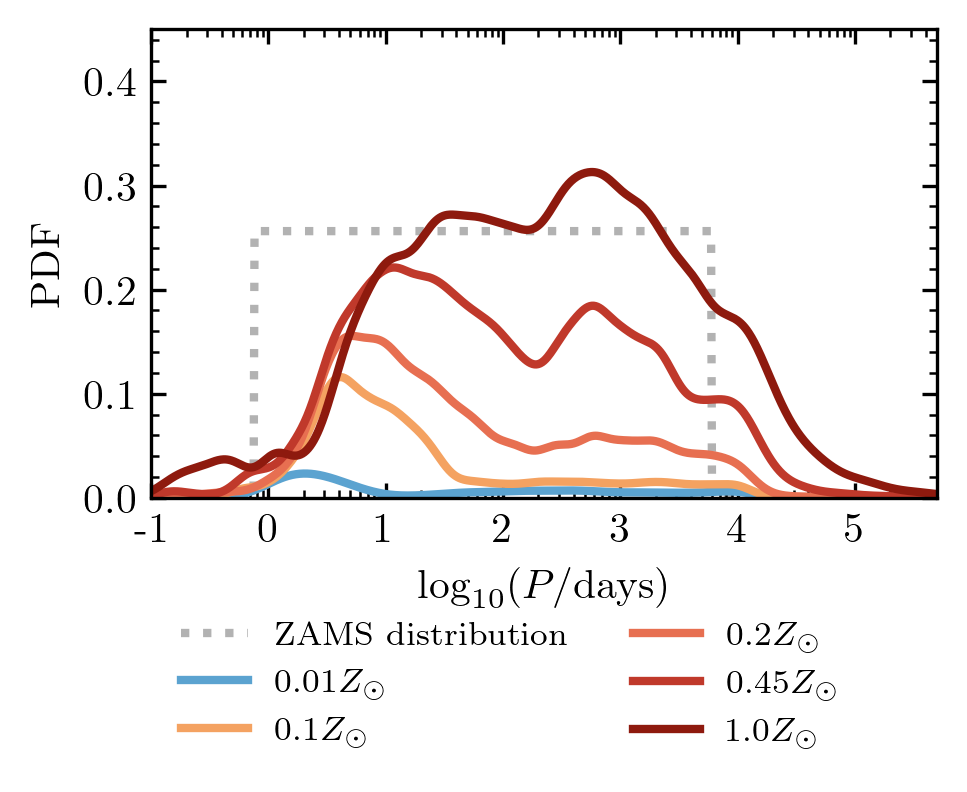

In [5]:

LOG_P_MIN = -1
LOG_P_MAX = 7

fig, ax = plt.subplots(1, 1, figsize=(3.38, 2.535*0.8))
metallicity_labels = ['0.01', '0.1', '0.2', '0.45', '1.0']

PDF_logP = PowerLawPeriod(p_min=0.75, p_max=6000.0, slope=0.0)
x_eval = np.linspace(LOG_P_MIN, LOG_P_MAX, 1000)

flatP = PDF_logP.pdf(10**x_eval)
ax.plot(10**x_eval, flatP, ':',
        color='black', linewidth=2, alpha=0.3, 
         label=f'ZAMS distribution')

mask_1Zsun = make_binary_mask(WR_data[1.0])
WNL_1Zsun, WNE_1Zsun, WC_1Zsun = classify_WR(WR_data[1.0])
weights_1Zsun = WR_data[1.0]['weight'] * WR_data[1.0]['model_weight']
Zsun_weight_total = np.sum(weights_1Zsun[mask_1Zsun & (WNL_1Zsun | WNE_1Zsun | WC_1Zsun)])

for met in metallicities:
    weights = WR_data[met]['weight'] * WR_data[met]['model_weight']
    period_array = WR_data[met]['period']
    mask = make_binary_mask(WR_data[met])
    WNL, WNE, WC = classify_WR(WR_data[met])
    kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC)]), weights=weights[mask & (WNL | WNE | WC)], bw_method=0.1)
    kde_eval = kde(x_eval)
    rescale =  np.sum(weights[mask & (WNL | WNE | WC)]) / Zsun_weight_total
    ax.plot(10**x_eval, kde_eval*rescale, color=COLORS[met], label=metallicity_labels[metallicities.index(met)]+'$Z_\odot$', linewidth=2)


# Housekeeping for layout
ax.set_xlabel('$\log_{10}(P/\mathrm{days})$')
ax.set_xscale('log')
ax.set_xlim(1e-1, 5e5)
ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
ax.set_ylim(0, 0.45)
ax.grid(False)
#ax.grid(True, which='major', ls='--', alpha=0.3)    
ax.set_ylabel('PDF')

ax.legend(bbox_to_anchor=(0.0, -0.2), loc='upper left', ncol=2)

figure_folder = FIGURE_DIR

plt.savefig(figure_folder / 'pdf' / 'metallicity_dependence.pdf', bbox_inches='tight')
plt.savefig(figure_folder / 'png' / 'metallicity_dependence.png', bbox_inches='tight', dpi=300)
plt.show()

# Different period distribution

In [6]:
from posydon.popsyn.distributions import Sana12Period


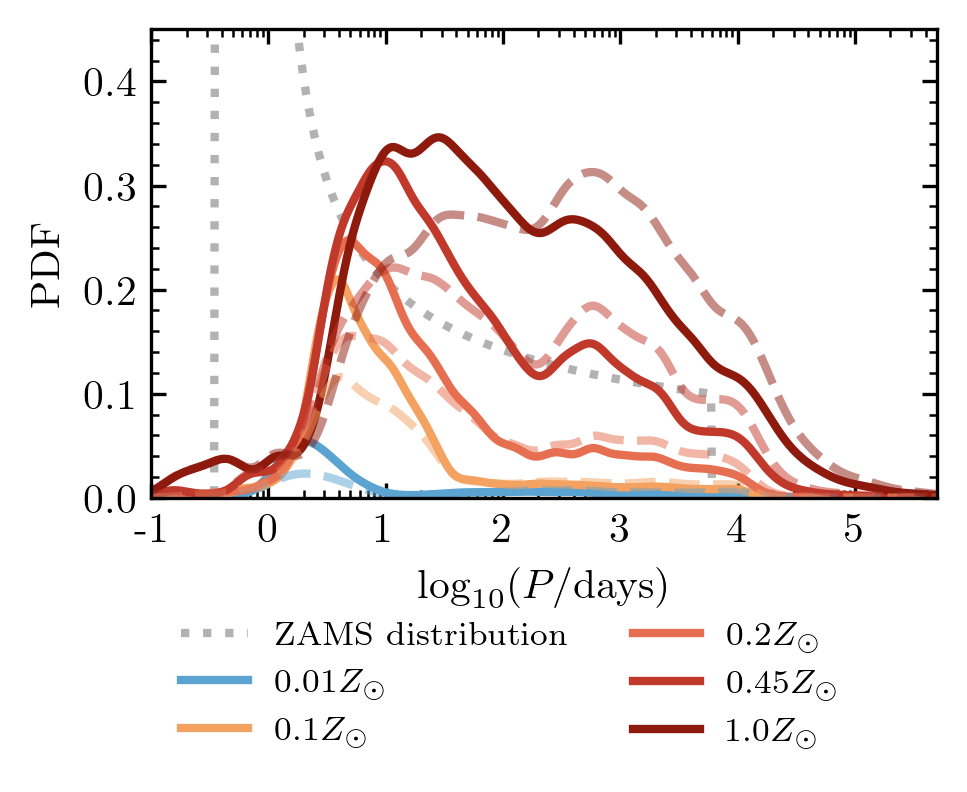

In [7]:

LOG_P_MIN = -1
LOG_P_MAX = 7

fig, ax = plt.subplots(1, 1, figsize=(3.38, 2.535*0.8))
metallicity_labels = ['0.01', '0.1', '0.2', '0.45', '1.0']
PDF_logP = Sana12Period()

x_eval = np.linspace(LOG_P_MIN, LOG_P_MAX, 1000)
flatP = PDF_logP.pdf(10**x_eval, m1=20)

ax.plot(10**x_eval, flatP, ':',
        color='black', linewidth=2, alpha=0.3, 
         label=f'ZAMS distribution')

mask_1Zsun = make_binary_mask(WR_data[1.0])
WNL_1Zsun, WNE_1Zsun, WC_1Zsun = classify_WR(WR_data[1.0])
weights_1Zsun = np.where(np.isclose(WR_data[1.0]['model_weight'],0.0), 0, WR_data[1.0]['weight'])


#weights_1Zsun = WR_data[1.0]['weight'] #* WR_data[1.0]['model_weight']
Zsun_weight_total = np.sum(weights_1Zsun[mask_1Zsun & (WNL_1Zsun | WNE_1Zsun | WC_1Zsun)])

for met in metallicities:
    weights = np.where(np.isclose(WR_data[met]['model_weight'], 0.0), 0, WR_data[met]['weight'])
    period_array = WR_data[met]['period']
    mask = make_binary_mask(WR_data[met])
    WNL, WNE, WC = classify_WR(WR_data[met])
    kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC)]), weights=weights[mask & (WNL | WNE | WC)], bw_method=0.1)
    kde_eval = kde(x_eval)
    rescale =  np.sum(weights[mask & (WNL | WNE | WC)]) / Zsun_weight_total
    ax.plot(10**x_eval, kde_eval*rescale, color=COLORS[met], label=metallicity_labels[metallicities.index(met)]+'$Z_\odot$', linewidth=2)



mask_1Zsun = make_binary_mask(WR_data[1.0])
WNL_1Zsun, WNE_1Zsun, WC_1Zsun = classify_WR(WR_data[1.0])
weights_1Zsun = WR_data[1.0]['weight'] * WR_data[1.0]['model_weight']
Zsun_weight_total = np.sum(weights_1Zsun[mask_1Zsun & (WNL_1Zsun | WNE_1Zsun | WC_1Zsun)])

for met in metallicities:
    weights = WR_data[met]['weight'] * WR_data[met]['model_weight']
    period_array = WR_data[met]['period']
    mask = make_binary_mask(WR_data[met])
    WNL, WNE, WC = classify_WR(WR_data[met])
    kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC)]), weights=weights[mask & (WNL | WNE | WC)], bw_method=0.1)
    kde_eval = kde(x_eval)
    rescale =  np.sum(weights[mask & (WNL | WNE | WC)]) / Zsun_weight_total
    ax.plot(10**x_eval, kde_eval*rescale, color=COLORS[met], ls='--', alpha=0.5, linewidth=2)



# Housekeeping for layout
ax.set_xlabel('$\log_{10}(P/\mathrm{days})$')
ax.set_xscale('log')
ax.set_xlim(1e-1, 5e5)
ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
ax.set_ylim(0, 0.45)
ax.grid(False)
#ax.grid(True, which='major', ls='--', alpha=0.3)    
ax.set_ylabel('PDF')

ax.legend(bbox_to_anchor=(0.0, -0.2), loc='upper left', ncol=2)

figure_folder = FIGURE_DIR

plt.savefig(figure_folder / 'pdf' / 'metallicity_dependence_Sana12.pdf', bbox_inches='tight')
plt.savefig(figure_folder / 'png' / 'metallicity_dependence_Sana12.png', bbox_inches='tight', dpi=300)
plt.show()

# Tau=0.5 boundary

Z = 0.01 Zsun
number of models: 418173
unique models: 44899
weighted: 68.50122925288818


Z = 0.1 Zsun
number of models: 924870
unique models: 79107
weighted: 246.89309369417253


Z = 0.2 Zsun
number of models: 1588203
unique models: 89559
weighted: 441.6601309933234


Z = 0.45 Zsun
number of models: 2411692
unique models: 88283
weighted: 750.0146177828993


Z = 1.0 Zsun
number of models: 3266623
unique models: 92006
weighted: 1119.4168046671907


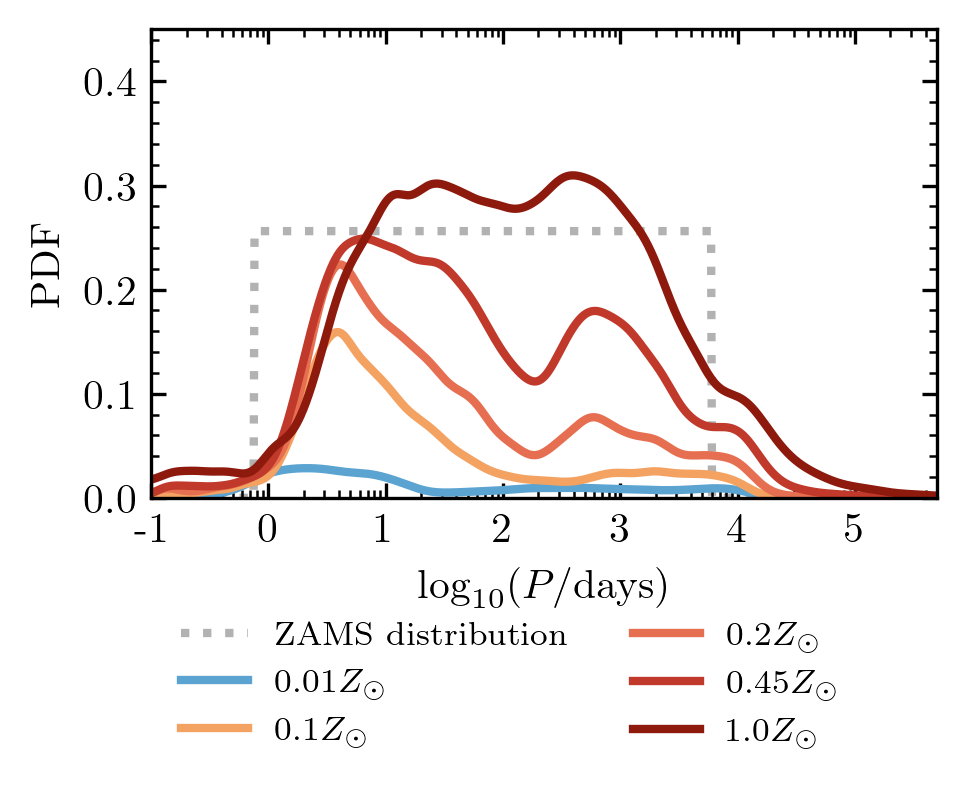

In [8]:

LOG_P_MIN = -1
LOG_P_MAX = 7

fig, ax = plt.subplots(1, 1, figsize=(3.38, 2.535*0.8))
metallicity_labels = ['0.01', '0.1', '0.2', '0.45', '1.0']

PDF_logP = PowerLawPeriod(p_min=0.75, p_max=6000.0, slope=0.0)
x_eval = np.linspace(LOG_P_MIN, LOG_P_MAX, 1000)

flatP = PDF_logP.pdf(10**x_eval)
ax.plot(10**x_eval, flatP, ':',
        color='black', linewidth=2, alpha=0.3, 
         label=f'ZAMS distribution')

mask_1Zsun = make_binary_mask(WR_data[1.0])
WNL_1Zsun, WNE_1Zsun, WC_1Zsun = classify_WR_optical_depth(WR_data[1.0])
weights_1Zsun = WR_data[1.0]['weight'] * WR_data[1.0]['model_weight']
Zsun_weight_total = np.sum(weights_1Zsun[mask_1Zsun & (WNL_1Zsun | WNE_1Zsun | WC_1Zsun)])

for met in metallicities:
    weights = WR_data[met]['weight'] * WR_data[met]['model_weight']
    period_array = WR_data[met]['period']
    mask = make_binary_mask(WR_data[met])
    WNL, WNE, WC = classify_WR_optical_depth(WR_data[met])
    kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC)]), weights=weights[mask & (WNL | WNE | WC)], bw_method=0.1)
    kde_eval = kde(x_eval)
    rescale =  np.sum(weights[mask & (WNL | WNE | WC)]) / Zsun_weight_total
    ax.plot(10**x_eval, kde_eval*rescale, color=COLORS[met], label=metallicity_labels[metallicities.index(met)]+'$Z_\odot$', linewidth=2)
    print(f"Z = {met} Zsun")
    print("number of models:", np.sum(mask & (WNL | WNE | WC)))
    print('unique models:', len(np.unique(WR_data[met]['key'][mask & (WNL | WNE | WC)])))
    print('weighted:',np.sum(weights[mask & (WNL | WNE | WC)]))


# Housekeeping for layout
ax.set_xlabel('$\log_{10}(P/\mathrm{days})$')
ax.set_xscale('log')
ax.set_xlim(1e-1, 5e5)
ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
ax.set_ylim(0, 0.45)
ax.grid(False)
#ax.grid(True, which='major', ls='--', alpha=0.3)    
ax.set_ylabel('PDF')

ax.legend(bbox_to_anchor=(0.0, -0.2), loc='upper left', ncol=2)

figure_folder = FIGURE_DIR

plt.savefig(figure_folder / 'pdf' / 'metallicity_dependence_lower_optical_depth.pdf', bbox_inches='tight')
plt.savefig(figure_folder / 'png' / 'metallicity_dependence_lower_optical_depth.png', bbox_inches='tight', dpi=300)
plt.show()

# Mass distributions

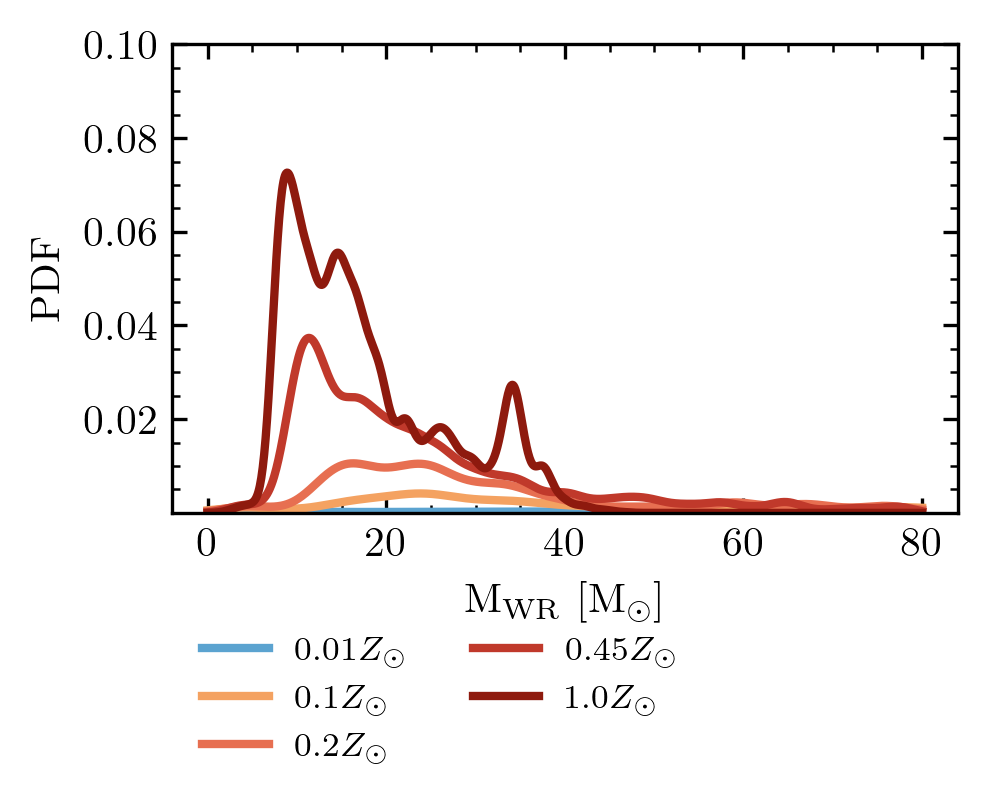

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(3.38, 2.535*0.8))
metallicity_labels = ['0.01', '0.1', '0.2', '0.45', '1.0']

#PDF_logP = PowerLawPeriod(p_min=0.75, p_max=6000.0, slope=0.0)
#x_eval = np.linspace(LOG_P_MIN, LOG_P_MAX, 1000)

#flatP = PDF_logP.pdf(10**x_eval)
#ax.plot(10**x_eval, flatP, ':',
#        color='black', linewidth=2, alpha=0.3, 
#         label=f'ZAMS distribution')

x_eval = np.linspace(0, 80, 1000)

mask_1Zsun = make_binary_mask(WR_data[1.0])
WNL_1Zsun, WNE_1Zsun, WC_1Zsun = classify_WR(WR_data[1.0])
weights_1Zsun = WR_data[1.0]['weight'] * WR_data[1.0]['model_weight']
Zsun_weight_total = np.sum(weights_1Zsun[mask_1Zsun & (WNL_1Zsun | WNE_1Zsun | WC_1Zsun)])

for met in metallicities:
    weights = WR_data[met]['weight'] * WR_data[met]['model_weight']
    mass_array = WR_data[met]['mass']
    mask = make_binary_mask(WR_data[met])
    WNL, WNE, WC = classify_WR(WR_data[met])
    kde = gaussian_kde(mass_array[mask & (WNL | WNE | WC)], weights=weights[mask & (WNL | WNE | WC)])
    kde_eval = kde(x_eval)
    rescale =  np.sum(weights[mask & (WNL | WNE | WC)]) / Zsun_weight_total
    ax.plot(x_eval, kde_eval*rescale, color=COLORS[met], label=metallicity_labels[metallicities.index(met)]+'$Z_\odot$', linewidth=2)


# Housekeeping for layout
ax.set_xlabel('M$_\mathrm{WR}$ [$\mathrm{M}_\odot]$')
#ax.set_xscale('log')
#ax.set_xlim(1e-1, 5e5)
#ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
#ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
#ax.set_ylim(0, 0.45)
ax.grid(False)
#ax.grid(True, which='major', ls='--', alpha=0.3)    
ax.set_ylabel('PDF')
#ax.set_yscale('log')
ax.set_ylim(1e-5,0.1)
ax.legend(bbox_to_anchor=(0.0, -0.2), loc='upper left', ncol=2)

figure_folder = FIGURE_DIR

#plt.savefig(figure_folder / 'pdf' / 'metallicity_dependence.pdf', bbox_inches='tight')
#plt.savefig(figure_folder / 'png' / 'metallicity_dependence.png', bbox_inches='tight', dpi=300)
plt.show()